In [9197]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


from scipy import stats


# Note: (so I don't forget) all fit_transforms may need to contain y_train with the X_train

Another thing, do we potentially keep rfs, what if it correlates with the other data?

Another note: outlier handling in rfs: https://careerfoundry.com/en/blog/data-analytics/how-to-find-outliers/#finding-outliers:~:text=Notice%20the%20data%20does%20not%20follow%20a%20normal%20distribution.%20Since%20the%20data%20is%20skewed%2C%20instead%20of%20using%20a%20z%2Dscore%20we%20can%20use%20interquartile%20range%20(IQR)%20to%20determine%20the%20outliers

Another note: keep index when creating a new dataframe from an already existing one

Another note: try fixing seaborn histograms in balancing section (feature preprocessing)

Another note: handle outliers in rfs for regression

# pcr-classification
This notebook is split into n sections, discussing the iterative approach to predicting the 'pCR (outcome)' outcome.

These sections include:
- [Data Preprocessing]
- Feature Selection / Dimensionality Reduction
- Machine Learnining Method Development
- Method Evaluation

The first two sections contain variations in approach to improving the quality of the following two sections, which are more focused on demonstrating what has been learnt about the data.

# Data preprocessing
Includes any change made to the data before applying feature selection: imputation, normalisation, bootstrapping,

### Before Preprocessing

In [9198]:
# verifying data and datatypes (numerical / categorical)
dataset = pd.read_csv("./datasets/TrainDataset2025.csv")

dataset.info()
dataset.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, ID to original_ngtdm_Strength
dtypes: float64(108), int64(12), object(1)
memory usage: 378.2+ KB


,ID,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,TRG002174,1,144.0,41.0,0,0,0,1,3,3,...,0.517172,0.375126,3.325332,0.002314,3880771.500,473.464852,0.000768,0.182615,0.030508,0.000758
1,TRG002178,0,142.0,39.0,1,1,0,0,3,3,...,0.444391,0.444391,3.032144,0.005612,2372009.744,59.459710,0.004383,0.032012,0.001006,0.003685
2,TRG002204,1,135.0,31.0,0,0,0,1,2,1,...,0.534549,0.534549,2.485848,0.006752,1540027.421,33.935384,0.007584,0.024062,0.000529,0.006447
3,TRG002206,0,12.0,35.0,0,0,0,1,3,3,...,0.506185,0.506185,2.606255,0.003755,6936740.794,46.859265,0.005424,0.013707,0.000178,0.004543
4,TRG002210,0,109.0,61.0,1,0,0,0,2,1,...,0.462282,0.462282,2.809279,0.006521,1265399.054,39.621023,0.006585,0.034148,0.001083,0.005626


In [9199]:
# Split data into features and outcomes

## Outcomes
dataset_y_clf = dataset['pCR (outcome)']

## Features
dataset_x_all = dataset.drop(['pCR (outcome)', 'RelapseFreeSurvival (outcome)'], axis=1) # should the RFS outcome be kept, is there potential correlation between it and pCR?


dataset_x_all # View all features

,ID,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,TRG002174,41.0,0,0,0,1,3,3,1,1,...,0.517172,0.375126,3.325332,0.002314,3.880772e+06,473.464852,0.000768,0.182615,0.030508,0.000758
1,TRG002178,39.0,1,1,0,0,3,3,1,1,...,0.444391,0.444391,3.032144,0.005612,2.372010e+06,59.459710,0.004383,0.032012,0.001006,0.003685
2,TRG002204,31.0,0,0,0,1,2,1,1,0,...,0.534549,0.534549,2.485848,0.006752,1.540027e+06,33.935384,0.007584,0.024062,0.000529,0.006447
3,TRG002206,35.0,0,0,0,1,3,3,1,1,...,0.506185,0.506185,2.606255,0.003755,6.936741e+06,46.859265,0.005424,0.013707,0.000178,0.004543
4,TRG002210,61.0,1,0,0,0,2,1,1,0,...,0.462282,0.462282,2.809279,0.006521,1.265399e+06,39.621023,0.006585,0.034148,0.001083,0.005626
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,TRG002948,58.5,1,0,1,0,3,2,1,1,...,0.476493,0.476493,2.453583,0.003229,2.327038e+06,18.562377,0.013766,0.018042,0.000288,0.012257
396,TRG002954,34.3,0,0,0,1,3,3,1,0,...,0.418382,0.418382,2.995603,0.004243,1.005061e+06,156.627179,0.002228,0.136015,0.022148,0.002098
397,TRG002958,53.3,0,0,0,1,2,1,1,0,...,0.527779,0.527778,1.500000,0.003728,2.132007e+05,0.996746,0.252582,0.007380,0.000037,0.231059
398,TRG002961,68.8,1,0,0,0,3,3,1,1,...,0.313693,0.313693,3.573557,0.001112,2.008034e+07,204.864200,0.001372,0.054063,0.003697,0.001368


## Type-specific preprocessing
### Dataset datatypes include: object, float64 and int64
- object: ID Column
- float64: Continuous features
- int64: Categorical features
- 999 (null): Change to NaN

### Handling object datatype
1. Remove object datatype

Remove the ID feature as it is for indexing, instead of a relevant feature

In [9200]:
# Handling object datatype
print(dataset_x_all.select_dtypes(object)) # ID Column

print("Before: "+str(dataset_x_all.select_dtypes(object).shape))

dataset_x_all = dataset_x_all.drop("ID",axis=1)
print("After: "+str(dataset_x_all.select_dtypes(object).shape))


            ID
0    TRG002174
1    TRG002178
2    TRG002204
3    TRG002206
4    TRG002210
..         ...
395  TRG002948
396  TRG002954
397  TRG002958
398  TRG002961
399  TRG002962

[400 rows x 1 columns]
Before: (400, 1)
After: (400, 0)


### Handling int64 datatype
#### Categorical Features
1. Remove non-categorical features

'original_shape_VoxelVolume' feature is int datatype, but not actually categorical data (doesn't use discrete data)

In [9201]:
print(f"Before: {dataset_x_all.select_dtypes(np.int64).shape}")
print(dataset_x_all.select_dtypes(np.int64).columns)

dataset_x_all['original_shape_VoxelVolume'] = dataset_x_all['original_shape_VoxelVolume'].astype(np.float64)

print(f"\nAfter: {dataset_x_all.select_dtypes(np.int64).shape}")
print(dataset_x_all.select_dtypes(np.int64).columns)

# Save column names of categorical features for later
categorical_names = dataset_x_all.select_dtypes(np.int64).columns

Before: (400, 11)
Index(['ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade', 'Proliferation',
       'HistologyType', 'LNStatus', 'TumourStage', 'Gene',
       'original_shape_VoxelVolume'],
      dtype='object')

After: (400, 10)
Index(['ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade', 'Proliferation',
       'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')


### Handling float64 datatype
#### Continuous Features

Age is considered a continuous feature as there are continuous values in data
- Considered converting to int, but this would truncate potentially valuable data and lead to Curse of Dimensionality, especially if using One-hot encoding.

In [9202]:
# Save column names of continuous features for later
# dataset_x_all['null'] = np.nan # view the effect of null data on the process
dataset_x_all.select_dtypes(np.float64)
continuous_names = dataset_x_all.select_dtypes(np.float64).columns

print(f"Continuous Feature Total: {len(continuous_names)}")
print(continuous_names)

Continuous Feature Total: 108
Index(['Age', 'original_shape_Elongation', 'original_shape_Flatness',
       'original_shape_LeastAxisLength', 'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter', 'original_shape_MeshVolume',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],
      dtype='object', length=108)


### Handling 999 
#### (null) datatype
1. Conversion to NaN

Issue: Can't replace all '999' with np.nan. This converts int64 to float64 as NaN is float64
- Solution: by saving column names, in datatype-specific handling, for int64 (categorical) features, no longer a need to preserve int64 as no data is lost when converting to float.
Note: could instead replace categorical features with pd.NA, but this has conflicts in some methods

In [9203]:
# Replace 999 (placeholder) with actual null values
dataset_x_all = dataset_x_all.replace([999], np.nan)
dataset_y_clf = dataset_y_clf.replace([999], np.nan)

In [9204]:
# # Drop instances of null data in y
# null_y = dataset_y_clf.loc[dataset_y_clf.isnull()].index
# dataset_y_clf = dataset_y_clf.dropna()
# dataset_x_all = dataset_x_all.drop(null_y)

Note: issues with dropping null in y
1. Stratified sampling cannot be performed on a y (outcome) that contains null data. This is as it samples  based on the provided distribution. The above code removes null data as a fix.
2. This would ignore null data in the actual test set, losing marks for not predicting

Result: Do not perform stratified sampling, and instead fix issues with distribution after train-test split.

## General Preprocessing
1. Train-test split
2. Outlier handling
3. Null Handling
4. Balancing data (Frequency handling)
5. a - Data Normalisation | b - One-hot Encoding

### 1. Train-test split
This step is performed first to avoid data leakage between the training and testing data

The dataset is split into training and testing data to evaluate models, built on the training data, on the test data

Explanations:
- Before Balancing Data as this creates new data based on the provided dataset - causing data to leak from train to test
- Before Outlier handling as this is done using statistical methods (mean, stdev, etc) based on the distribution - leading to data leakage
- Before Data Imputation (same as outlier handling)


test_size - (try different ones possibly)

stratify - train/data will follow distribution of provided categorical outcomes

In [9205]:
# Split the X_train into 80% for training data and 20% for test data with stratified splitting to keep the balance of 0 and 1 classes in the training and test sets roughly the same
X_train, X_test, y_train, y_test = train_test_split(dataset_x_all, dataset_y_clf, test_size = 0.2, random_state = 12)

### 2. Outlier Handling
This step is in this position as it may lead to data imbalance, which is resolved later

Outliers can be imputed through removal, capping or statistical methods.
- Removal compromises the model due to limited training data (400 sample), and will be avoided
- Capping restricts the distribution of the model to a specific range.
- Statistical Methods function similarly to capping, using data, such as averages, to restrict the distribution range.

Options (continuous data): 
1. Z-Score
2. Interquartile Range
3. Isolation Forest
4. Local Outlier Factor

Options (categorical data):
1. Verifying Category Totals

#### Visualise outliers
- Note: normalisation is not actually performed on the dataset here, it only helps to illustrate the relative total of outliers which would otherwise be unclear due to differences in feature range.

<Axes: >

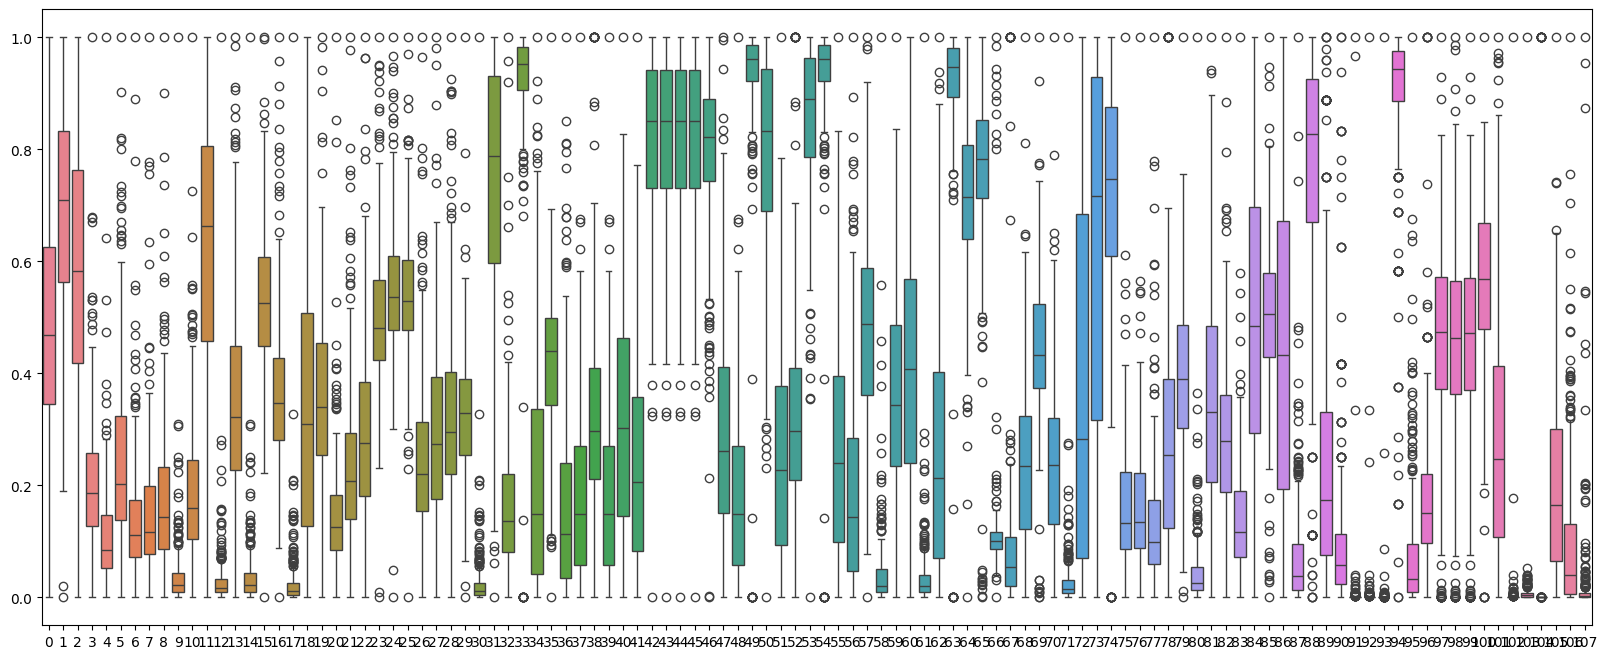

In [9206]:
scaler = MinMaxScaler()

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=scaler.fit_transform(X_train[continuous_names]),ax=ax)

#### Option 1 - Z-score
Determining outliers using mean and stdev of each feature

In [9207]:
# Get z scores for continuous data
z_scores = X_train[continuous_names].apply(stats.zscore) # concat y if doing rfs (process x and ys at same time)
abs_z_scores = np.abs(z_scores)
# abs_z_scores = abs_z_scores > 3
abs_z_scores[abs_z_scores.notnull()] = abs_z_scores > 3
print(f"Outlier total: {abs_z_scores.sum().sum()}")

# Output columns containing z scores
z_outlier_cols = abs_z_scores.sum()
z_outlier_cols = z_outlier_cols[z_outlier_cols > 0].sort_values(ascending=False)
print(f"\nOutlier Locations:\n{z_outlier_cols}")

Outlier total: 478

Outlier Locations:
original_glszm_LowGrayLevelZoneEmphasis            13
original_glszm_HighGrayLevelZoneEmphasis           13
original_gldm_LowGrayLevelEmphasis                 12
original_glcm_Autocorrelation                      12
original_gldm_HighGrayLevelEmphasis                12
                                                   ..
original_glcm_SumEntropy                            1
original_gldm_DependenceEntropy                     1
original_gldm_DependenceNonUniformityNormalized     1
original_gldm_GrayLevelVariance                     1
original_glcm_JointEntropy                          1
Length: 96, dtype: object


C:\Users\danie\AppData\Local\Temp\ipykernel_42740\139578827.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[[False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [Fa

In [9208]:
# # cap outliers using the lower/upper z-score of the column
# # ----------------------------

# # replace outliers with the median
# X_train[continuous_names] = np.where(z_scores < -3, X_train[continuous_names].median(), X_train[continuous_names])
# X_train[continuous_names] = np.where(z_scores > 3, X_train[continuous_names].median(), X_train[continuous_names])

In [9209]:
# Outputting result of z_score on dataset
z_scores = X_train[continuous_names].apply(stats.zscore) # concat y if doing rfs (process x and ys at same time)
abs_z_scores = np.abs(z_scores)
# abs_z_scores = abs_z_scores > 3
abs_z_scores[abs_z_scores.notnull()] = abs_z_scores > 3
print(f"Outlier total: {abs_z_scores.sum().sum()}")

z_outlier_cols = abs_z_scores.sum()
z_outlier_cols = z_outlier_cols[z_outlier_cols > 0].sort_values(ascending=False)
print(f"\nOutlier Locations:\n{z_outlier_cols}")

C:\Users\danie\AppData\Local\Temp\ipykernel_42740\2950960362.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[[False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [False]
 [F

Outlier total: 478

Outlier Locations:
original_glszm_LowGrayLevelZoneEmphasis            13
original_glszm_HighGrayLevelZoneEmphasis           13
original_gldm_LowGrayLevelEmphasis                 12
original_glcm_Autocorrelation                      12
original_gldm_HighGrayLevelEmphasis                12
                                                   ..
original_glcm_SumEntropy                            1
original_gldm_DependenceEntropy                     1
original_gldm_DependenceNonUniformityNormalized     1
original_gldm_GrayLevelVariance                     1
original_glcm_JointEntropy                          1
Length: 96, dtype: object


#### Option 2 - Interquartile Range

In [9210]:
# Calculating Interquartile Range for continuous
lower_quartile = X_train[continuous_names].quantile(0.25)
upper_quartile = X_train[continuous_names].quantile(0.75)
iqr = upper_quartile - lower_quartile

lower_bound = lower_quartile - 1.5 * iqr
upper_bound = upper_quartile + 1.5 * iqr

In [9211]:
# Outputting outlier total based on iqr
outliers_iqr = ((X_train[continuous_names] < (lower_quartile - 1.5 * iqr)) | (X_train[continuous_names] > (upper_quartile + 1.5 * iqr)))
print(f"Outlier total: {outliers_iqr.sum().sum()}")

# Outputting columns containing outliers based on iqr
iqr_outliers_col = outliers_iqr.sum()
iqr_outliers_col = iqr_outliers_col[iqr_outliers_col > 0].sort_values(ascending=False)
print(f"\nOutlier locations:\n{iqr_outliers_col}")

Outlier total: 1560

Outlier locations:
original_ngtdm_Coarseness                          51
original_ngtdm_Strength                            48
original_glszm_LargeAreaLowGrayLevelEmphasis       45
original_glszm_LargeAreaEmphasis                   43
original_glszm_ZoneVariance                        42
                                                   ..
original_glcm_SumEntropy                            1
original_glcm_DifferenceVariance                    1
original_gldm_DependenceNonUniformityNormalized     1
original_glcm_DifferenceEntropy                     1
original_glcm_JointEntropy                          1
Length: 99, dtype: int64


Note: Using IQR presents a similar issue with z-score as there are likely outliers across many rows. To avoid this, outliers are replaced with the median instead of removing the entire row.

In [9212]:
# cap outliers using the lower/upper bound of the column
X_train[continuous_names] = np.where(X_train[continuous_names] < lower_bound, lower_bound, X_train[continuous_names])
X_train[continuous_names] = np.where(X_train[continuous_names] > upper_bound, upper_bound, X_train[continuous_names])

# # replace outliers with the median
# X_train[continuous_names] = np.where((X_train[continuous_names] < lower_bound) | (X_train[continuous_names] > upper_bound), X_train[continuous_names].median(), X_train[continuous_names])

In [9213]:
# Outputting resultant number of outliers per continuous column
outliers_iqr = ((X_train[continuous_names] < (lower_quartile - 1.5 * iqr)) | (X_train[continuous_names] > (upper_quartile + 1.5 * iqr)))
print(f"Outlier total: {outliers_iqr.sum().sum()}")

iqr_outliers_col = outliers_iqr.sum()
iqr_outliers_col = iqr_outliers_col[iqr_outliers_col > 0].sort_values(ascending=False)
print(f"\nOutlier locations:\n{iqr_outliers_col}")

Outlier total: 0

Outlier locations:
Series([], dtype: int64)


#### Option 3 - Isolation Forest
Method of anomaly detection that isolates outliers by building decision trees based on multiple splits. This can be used to predict whether a sample is an outlier or not

Params include: contamination, random state and bootstrap [(among others that may be useful)](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#:~:text=IsolationForest-,IsolationForest,-%23)
- contamination (float) is the target percentage of outliers
- random state (int) is the pseudorandom seed
- bootstrap (bool) is an option to enable random sampling with replacement

In [9214]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05, random_state=42, bootstrap=True)
iso_predict = iso.fit_predict(X_train)
print(pd.DataFrame(iso_predict).value_counts())

0 
 1    304
-1     16
Name: count, dtype: int64


In [9215]:
# Hyperparameter tuning to use -------------------------------------------------------------------------

#### Option 4 - Local Outlier Factor

Note: this method requires non-null data, which is not possible for this implementation

In [9216]:
# from sklearn.neighbors import LocalOutlierFactor

# lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
# lof_predict = lof.fit_predict(X_train)

# print(pd.DataFrame(lof_predict).value_counts())

#### Verifying Category Totals

<Axes: >

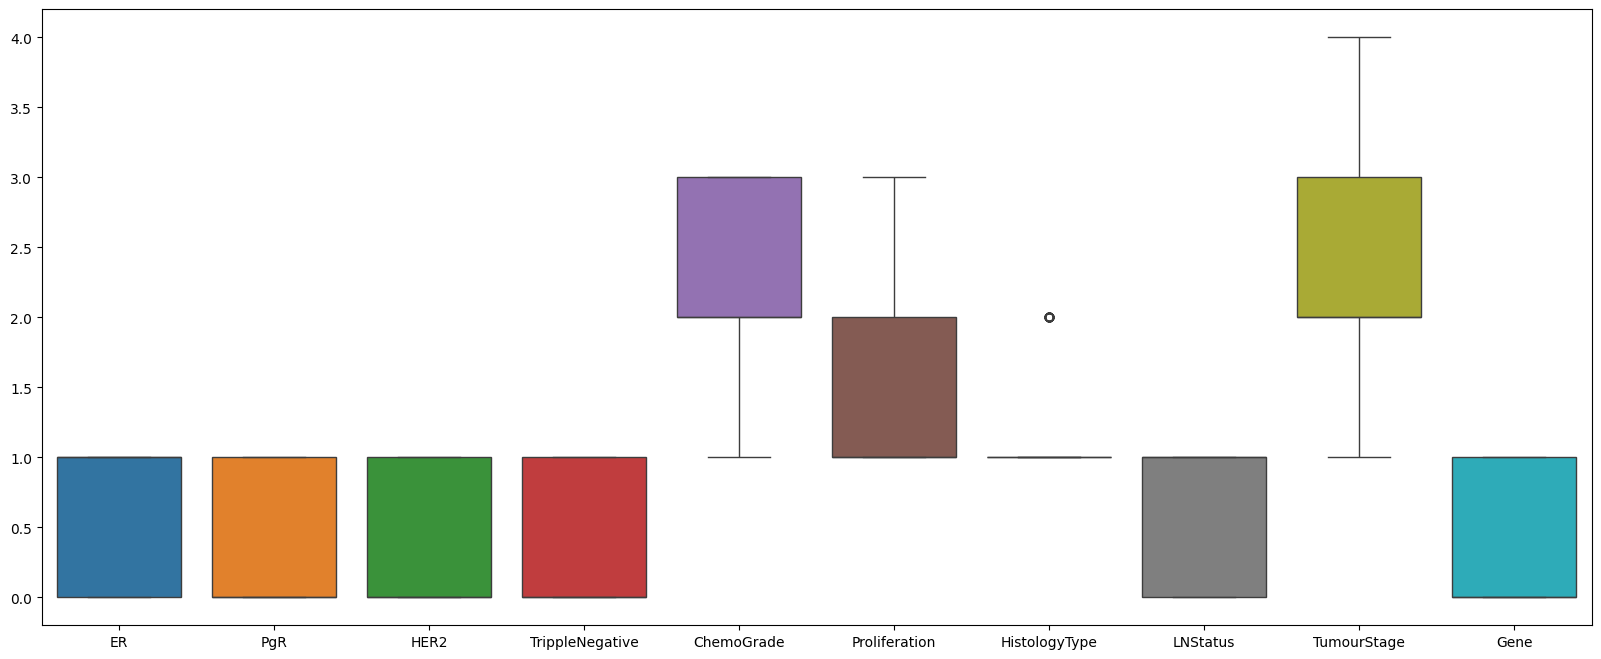

In [9217]:
# Check value counts for categorical data, replace any questionable instances
fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=X_train[categorical_names],ax=ax)

Note: the above data has values accurate with the documentation

In [9218]:
# Cap categorical data to a range, in case test data is outside of the defined range for each value
data_train_cat = pd.concat([y_train, X_train[categorical_names]], axis=1) # remove categorical data in rfs

categorical_ranges = {
    "pCR (outcome)": (0,1),
    "ER": (0, 1),
    "PgR": (0, 1),
    "HER2": (0, 1),
    "TrippleNegative": (0, 1),
    "ChemoGrade": (1, 3),
    "Proliferation": (1, 3),
    "HistologyType": (1, 2),
    "LNStatus": (0, 1),
    "TumourStage": (1, 4),
    "Gene": (0, 1)
}

for col in data_train_cat.columns:
    # print(f"{col}: {X_train[col].max()} to {X_train[col].min()}")
    
    # Truncate data to be within range for categorical features
    data_train_cat[col] = np.where(data_train_cat[col] > categorical_ranges[col][1], categorical_ranges[col][1],  data_train_cat[col])
    data_train_cat[col] = np.where(data_train_cat[col] < categorical_ranges[col][0], categorical_ranges[col][0],  data_train_cat[col])

y_train = data_train_cat['pCR (outcome)']
X_train[categorical_names] = data_train_cat.drop(['pCR (outcome)'], axis=1)

### 3. Null Handling
This step is performed after outlier handling as methods handling nulls based on the distribution, such as statistical ones, should perform better with a more accurate distribution.

Null values can be removed or replaced, or a combination of both. Consider only removing Gene null values, as other null totals are minimal
- SimpleImputer for replacement by mean/mode/median
- More Complex Imputers **(chosen imputation category)**

Note: in retrospect, as null data is in the test set, null values cannot be removed. This is as we want to make a predicition for each sample

#### SimpleImputer

Options:
1. Removal of all null values
2. Partial Removal, Partial Replacement
3. Replacement of all null values

This class' constructor has a 'missing_values' field, meaning we could set said field to 999 instead of the earlier conversion of 999 to NaN
- Prefer not to do so as '999' would negatively affect algorithms (such as IQR and z-score)

Drawback - requires looking at individual feature [distribution](https://medium.com/@silva.f.francis/techniques-for-data-imputation-in-data-science-a-technical-review-85a626b079dd#:~:text=2.1.1%20Mean%2C%20Median%2C%20and%20Mode%20Imputation)

In [9219]:
# Outputting null values: before imputation
print("Before Imputation:")
data_train = pd.concat([y_train, X_train], axis=1)
                       
non_null = data_train.isnull().sum()
non_null = non_null[non_null > 0].sort_values(ascending=False)
non_null

Before Imputation:


Gene             69
pCR (outcome)     4
ChemoGrade        3
HistologyType     3
Proliferation     2
LNStatus          1
dtype: int64

Note: The Gene feature should potentially be handled differently, considering the large amount of null data

##### 1. Removal of all null values
Majority of null values are from one feature ('Gene'). This method does not consider whether data with less outliers should be handled differently?

In [9220]:
# # Removal (entirely)
# X_train = X_train.dropna()

##### 2. Partial Removal, Partial Replacement
Steps:
1. Removing Gene
2. Imputing other features (format: x|y -> continuous|categorical)

    2.1 Mean|Mode Replacement

    2.2 Mode|Mode Replacement
    
    2.3 Median|Mode Replacement

Replace categorical features using the mode and choose method for  categorical features based on effect on output

Removes the majority of outliers ('Gene'), replaces the rest.

In [9221]:
# np.nan is default value to be imputed

imputer_mean = SimpleImputer(strategy='mean')
imputer_mode = SimpleImputer(strategy='most_frequent')
imputer_median = SimpleImputer(strategy = 'median')

In [9222]:
# ## 1. Removing Gene
# X_train['Gene'].dropna()

# ## 2. Replacing other features (format: x|y -> continuous|categorical)
# X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names], y_train)

# # ### 2.1 Mean|Mode
# # X_train[continuous_names] = imputer_mean.fit_transform(X_train[continuous_names])  

# # ### 2.2 Mode|Mode
# # X_train[continuous_names] = imputer_mean.fit_transform(X_train[continuous_names])  

# ### 2.3 Median|Mode
# X_train[continuous_names] = imputer_median.fit_transform(X_train[continuous_names], y_train)

Note: for similar reasons to removal of null values, we can't remove null data, but have to replace it

##### 3. Replacement of all null values

(format: x|y -> continuous|categorical)
1. Replacing using mean|mode
2. Replacing using the median|mode


1. Replacing using mean|mode

In [9223]:
# X_train[continuous_names] = imputer_median.fit_transform(X_train[continuous_names])
# X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names])

2. Replacing using the median|mode

In [9224]:
# X_train[continuous_names] = imputer_median.fit_transform(X_train[continuous_names])
# X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names])

Note: The above methods are all very naive, possibly try using more complex imputation.

#### More Complex Imputers

Note: These methods cannot impute 'pCR (outcome)' as it contains NaN, making the datatype np.float64. This leads to imputed values being continuous. pd.NA, as an alternative, is ambiguous to these methods and also cannot be used.

##### KNNImputer **(chosen imputation method)**

1. Nearest neighbour imputation (different scales in features may be punishing)

In [9225]:
from sklearn.impute import KNNImputer
imputer_knn = KNNImputer(n_neighbors=2, weights="uniform")

X_train = pd.DataFrame(imputer_knn.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

##### IterativeImputer

Imputer fits to the data iteratively

Note: experimental

In [9226]:
# from sklearn.experimental import enable_iterative_imputer
# from sklearn.impute import IterativeImputer
# imputer_iter = IterativeImputer(max_iter=10, random_state=0)

# X_train = pd.DataFrame(imputer_iter.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

#### Null values after imputation

In [9227]:
# Imputing 'pCR (Outcome)' using mode
y_train = pd.DataFrame(imputer_mode.fit_transform(pd.DataFrame(y_train)), columns=['pCR (outcome)'], index=y_train.index)

# Convert categoricals back to int64 (no more NaN/float64)
y_train = y_train.astype(np.int64)
X_train[categorical_names] = X_train[categorical_names].astype(np.int64)

In [9228]:
# Outputting null values: after imputation
print("After Imputation:")
data_train = pd.concat([y_train, X_train], axis=1)
                       
non_null = data_train.isnull().sum()
non_null = non_null[non_null > 0].sort_values(ascending=False)
non_null

After Imputation:


Series([], dtype: int64)

### 4. Balancing Data
The outcome distribution of data will be imbalanced following previous steps. This step focuses on fixing this. 

- Applies for classification as we split based on discrete outcome
- Question: How do we apply to regression? (normal distribution)

1. Viewing Outcome Imbalance 
2. Sampling New Data

#### 1. Viewing Outcome Imbalance 
Use a histogram to view relative frequencies

In [9229]:
# View balancing
print(y_train.value_counts())

# sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
# sns.countplot(x=y_train, data=X_train)

pCR (outcome)
0                252
1                 68
Name: count, dtype: int64


#### 2. Sampling New Data
Options:
- Random Sampling
- SMOTE **(chosen balancing method)**

Generative Options:
- Variational Autoencoder (VAE)
- Generative Adversarial Autoencoder (GAN)
- VAE-GAN? (to mitigate issues with either method)

Aim is to generate new data to fix balancing issues

### Random Sampling
- Random Oversampling
- Random Undersampling
- Bootstrapping (Random Sampling + replacement)

In [9230]:
from sklearn.utils import resample
df = pd.concat([y_train, X_train], axis=1)
min_class = df.loc[df['pCR (outcome)'] == 1]
maj_class = df.loc[df['pCR (outcome)'] == 0]
df

,pCR (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
199,1,36.783025,0,1,0,0,3,3,1,0,...,0.350799,0.350799,3.197160,0.003696,9.762004e+05,74.501409,0.004012,0.102368,0.011175,0.003570
43,1,69.000000,0,0,1,0,2,1,1,1,...,0.550507,0.550507,2.573220,0.005959,1.052641e+06,21.346044,0.012082,0.024663,0.000567,0.010516
307,0,60.000000,0,0,0,1,2,1,1,1,...,0.426840,0.426840,2.956748,0.007522,4.830177e+05,38.839662,0.007064,0.066551,0.004116,0.006365
166,0,38.143737,1,1,1,0,3,2,1,0,...,0.572002,0.572002,2.000000,0.002920,1.720824e+06,8.240840,0.027536,0.011843,0.000150,0.020646
64,0,45.653662,0,0,1,0,3,2,1,0,...,0.584634,0.583599,2.398050,0.002764,1.202316e+07,163.782516,0.001637,0.033111,0.001479,0.001571
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,1,71.300000,0,0,0,1,3,3,1,1,...,0.411956,0.411956,3.573921,0.004671,8.211440e+06,369.781166,0.000618,0.073363,0.005057,0.000545
253,1,63.238877,0,0,1,0,2,3,1,1,...,0.409377,0.409376,3.305045,0.001730,6.755623e+06,369.781166,0.000653,0.117835,0.014701,0.000594
390,0,68.400000,0,0,0,1,3,2,1,1,...,0.476508,0.476508,2.755023,0.004610,1.456280e+06,34.211090,0.007661,0.035392,0.001197,0.006756
155,0,40.000000,1,1,0,0,2,1,1,1,...,0.404660,0.404660,3.386250,0.003987,2.235835e+06,104.017827,0.002675,0.070976,0.005043,0.002376


#### Random Oversampling

In [9231]:
maj_downsampled = resample(maj_class, replace=True, n_samples=len(min_class), random_state=42)

df_undersampled = pd.concat([maj_downsampled, min_class], axis=0)
df_undersampled

,pCR (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
13,0,47.000000,0,0,0,1,3,3,1,0,...,0.429904,0.429904,3.330874,0.004290,6.083001e+06,170.357955,0.001556,0.045200,0.001885,0.001360
97,0,63.783710,0,0,0,1,2,1,1,1,...,0.480230,0.480230,2.746266,0.007512,6.687649e+05,44.138139,0.006133,0.056968,0.003237,0.005226
392,0,28.300000,0,0,0,1,3,1,1,1,...,0.300230,0.300229,2.750000,0.003303,5.709332e+05,13.723543,0.019693,0.041933,0.002050,0.019120
180,0,70.447639,1,0,0,0,2,1,2,1,...,0.604370,0.604370,2.020921,0.005144,9.260675e+05,8.441428,0.027536,0.013172,0.000143,0.020646
129,0,51.887748,0,0,0,1,2,1,2,1,...,0.681026,0.681026,1.594001,0.009838,3.175554e+05,117.201813,0.003225,0.113427,0.019483,0.003167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,1,42.000000,0,0,0,1,2,1,1,0,...,0.761571,0.747629,0.962921,0.002413,1.025539e+06,1.066502,0.027536,0.002932,0.000007,0.020646
278,1,56.100000,0,0,1,0,2,1,1,0,...,0.450197,0.450197,2.696620,0.005424,5.838047e+05,40.573423,0.006890,0.074964,0.005729,0.005909
332,1,38.800000,0,0,0,1,3,3,1,0,...,0.500205,0.500204,1.500000,0.003231,2.651168e+05,5.377756,0.027536,0.033193,0.001082,0.020646
241,1,71.300000,0,0,0,1,3,3,1,1,...,0.411956,0.411956,3.573921,0.004671,8.211440e+06,369.781166,0.000618,0.073363,0.005057,0.000545


#### Random Undersampling

In [9232]:
min_upsampled = resample(min_class, replace=True, n_samples=len(maj_class), random_state=42)

df_oversampled = pd.concat([min_upsampled, maj_class], axis=0) 
df_oversampled

,pCR (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
182,1,55.400000,0,0,0,1,2,1,2,0,...,0.526156,0.526156,2.395999,0.003362,1.100482e+06,82.013581,0.003698,0.106960,0.012224,0.003344
83,1,50.757016,1,1,0,0,2,1,2,0,...,0.607302,0.607287,2.471092,0.002290,2.323460e+07,44.771862,0.005623,0.005903,0.000032,0.004735
100,1,69.040383,1,1,1,0,2,1,1,1,...,0.402102,0.402102,3.450875,0.003277,1.128978e+07,353.274140,0.000777,0.061154,0.003952,0.000669
351,1,42.700000,0,0,0,1,3,3,1,0,...,0.374829,0.374829,3.201460,0.004586,1.180094e+06,53.909560,0.005069,0.062390,0.003892,0.004351
222,1,61.078713,1,1,1,0,2,1,2,0,...,0.458844,0.458843,3.307746,0.004389,5.897628e+06,178.426869,0.001489,0.043025,0.001870,0.001299
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259,0,34.201232,1,1,0,0,2,1,1,0,...,0.510417,0.510417,1.792481,0.000431,1.756624e+07,332.095590,0.001021,0.140656,0.019483,0.000951
130,0,34.390144,0,0,0,1,3,2,1,1,...,0.604588,0.574346,2.426142,0.004041,6.897427e+06,369.781166,0.000592,0.088001,0.011752,0.000583
390,0,68.400000,0,0,0,1,3,2,1,1,...,0.476508,0.476508,2.755023,0.004610,1.456280e+06,34.211090,0.007661,0.035392,0.001197,0.006756
155,0,40.000000,1,1,0,0,2,1,1,1,...,0.404660,0.404660,3.386250,0.003987,2.235835e+06,104.017827,0.002675,0.070976,0.005043,0.002376


#### Applying Random Sampling

In [9233]:
# Split data again into features and outcomes

# Oversampling
# y_train = df_oversampled['pCR (outcome)']
# X_train = df_oversampled.drop(['pCR (outcome)'], axis=1)

# Undersampling
# y_train = df_undersampled['pCR (outcome)']
# X_train = df_undersampled.drop(['pCR (outcome)'], axis=1)

#### Bootstrapping

### SMOTE **(chosen balancing method)**

In [9234]:
from imblearn.over_sampling import SMOTE

count_class = y_train.value_counts()
smote = SMOTE(sampling_strategy='minority')
X_train, y_train = smote.fit_resample(X_train, y_train)

### Variational Autoencoder (VAE)

### Generative Adversarial Autoencoder

In [9235]:
# import tensorflow as tf
# from tensorflow.keras import layers, models, optimizers
# from sklearn.preprocessing import MinMaxScaler
# import numpy as np


# # Normalize Data to [0, 1] for GAN training (common practice with sigmoid output)
# scaler = MinMaxScaler(feature_range=(-1, 1)) # Tanh activation range
# X_train_scaled = scaler.fit_transform(dataset_x_all)

In [9236]:
# # Building GAN

# latent_dim = 64 # Size of random noise vector
# data_dim = X_train_scaled.shape[1]

# # Generator
# def build_generator(latent_dim, data_dim):
#     model = tf.keras.Sequential()
#     model.add(layers.Dense(128, input_dim=latent_dim))
#     model.add(layers.LeakyReLU(alpha=0.2))
#     model.add(layers.BatchNormalization(momentum=0.8))
#     model.add(layers.Dense(256))
#     model.add(layers.LeakyReLU(alpha=0.2))
#     model.add(layers.BatchNormalization(momentum=0.8))
#     model.add(layers.Dense(data_dim, activation='tanh')) # Output scaled between -1 and 1
#     return model

# # Discriminator
# def build_discriminator(data_dim):
#     model = tf.keras.Sequential()
#     model.add(layers.Dense(256, input_dim=data_dim))
#     model.add(layers.LeakyReLU(alpha=0.2))
#     model.add(layers.Dropout(0.4))
#     model.add(layers.Dense(128))
#     model.add(layers.LeakyReLU(alpha=0.2))
#     model.add(layers.Dropout(0.4))
#     model.add(layers.Dense(1, activation='sigmoid')) # Output probability
#     return model

# generator = build_generator(latent_dim, data_dim)
# discriminator = build_discriminator(data_dim)

# # Compile Discriminator
# optimizer = optimizers.Adam(0.0002, 0.5)
# discriminator.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])

# # Combined Model (Stack Generator and Discriminator)
# # Train Generator to fool Discriminator
# discriminator.trainable = False
# z = layers.Input(shape=(latent_dim,))
# img = generator(z)
# validity = discriminator(img)
# combined = models.Model(z, validity)
# combined.compile(loss='binary_crossentropy', optimizer=optimizer)

In [9237]:
# # Train GAN
# epochs = 500 
# batch_size = 3 
# # Note: Batch size is tiny because dataset is tiny. 
# # In real scenarios, batch_size would be 32 or 64.

# valid = np.ones((batch_size, 1))
# fake = np.zeros((batch_size, 1))

# for epoch in range(epochs):
#     # Train Discriminator 
#     # Select a random batch of data (here, just the whole dataset essentially)
#     idx = np.random.randint(0, X_train_scaled.shape[0], batch_size)
#     real_data = X_train_scaled[idx]

#     # Generate noise and fake data
#     noise = np.random.normal(0, 1, (batch_size, latent_dim))
#     gen_data = generator.predict(noise, verbose=0)

#     # Train
#     d_loss_real = discriminator.train_on_batch(real_data, valid)
#     d_loss_fake = discriminator.train_on_batch(gen_data, fake)
#     d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

#     # Train Generator
#     noise = np.random.normal(0, 1, (batch_size, latent_dim))
#     g_loss = combined.train_on_batch(noise, valid)

#     if epoch % 100 == 0:
#         print(f"{epoch} [D loss: {d_loss[0]}, acc.: {100*d_loss[1]}%] [G loss: {g_loss}]")

In [9238]:
# # Generate New Data
# num_new_samples = 220
# noise = np.random.normal(0, 1, (num_new_samples, latent_dim))
# gen_data_scaled = generator.predict(noise)

# # 6. Post-process
# gen_data = scaler.inverse_transform(gen_data_scaled)
# gen_df = pd.DataFrame(gen_data, columns=dataset_x_all.columns)

# # Round categorical columns to nearest integer
# for col in categorical_names:
#     if col in gen_df.columns:
#         gen_df[col] = gen_df[col].round().astype(int)


# # Merge with original
# final_df = pd.concat([dataset_x_all, gen_df], ignore_index=True)
    
# final_df

### VAE-GAN

### Results: 
Viewing balanced data:

In [9239]:
# View balancing
print(y_train.value_counts())

# sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
# sns.countplot(x=y_train, data=X_train)

pCR (outcome)
0                252
1                252
Name: count, dtype: int64


### 5.a Normalisation
This step is the final in preprocessing as it handles the range, defined by previous steps, to the benefit of the major steps to follow.

Normalisation restricts the data to a specific range to make the model development process more robust, especially for distance based methods.

Options:
1. MinMax
2. Z-normalisation
3. Vector Normalisation

More research: https://www.geeksforgeeks.org/python/data-normalization-with-pandas/

##### Before Normalisation

<Axes: >

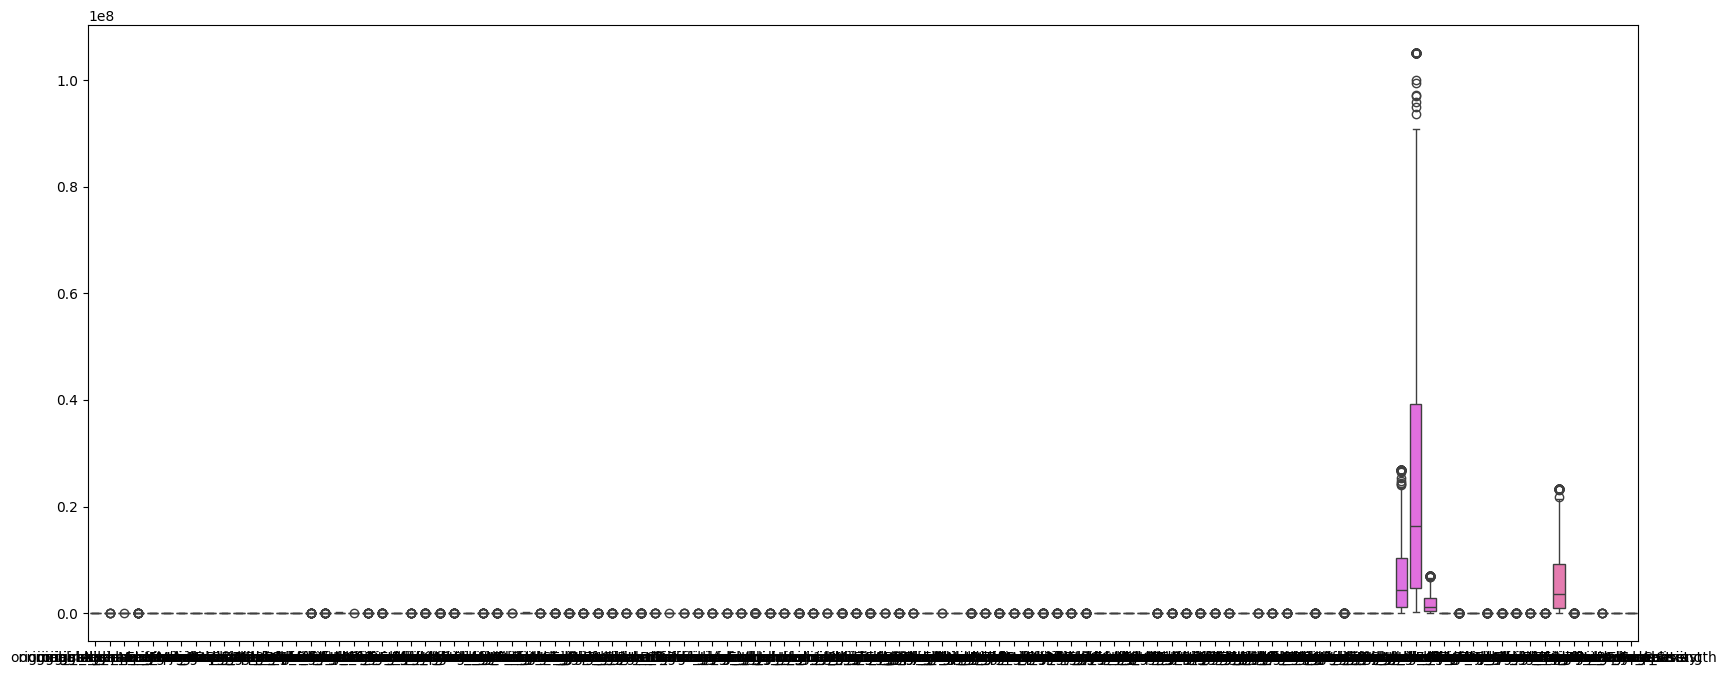

In [9241]:
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

##### 1. MinMax
Bounds data to 0-1 range based on the minimum and maximum for each feature. Has the benefit of being numerically robust, especially for distance-based methods like KNN.

<Axes: >

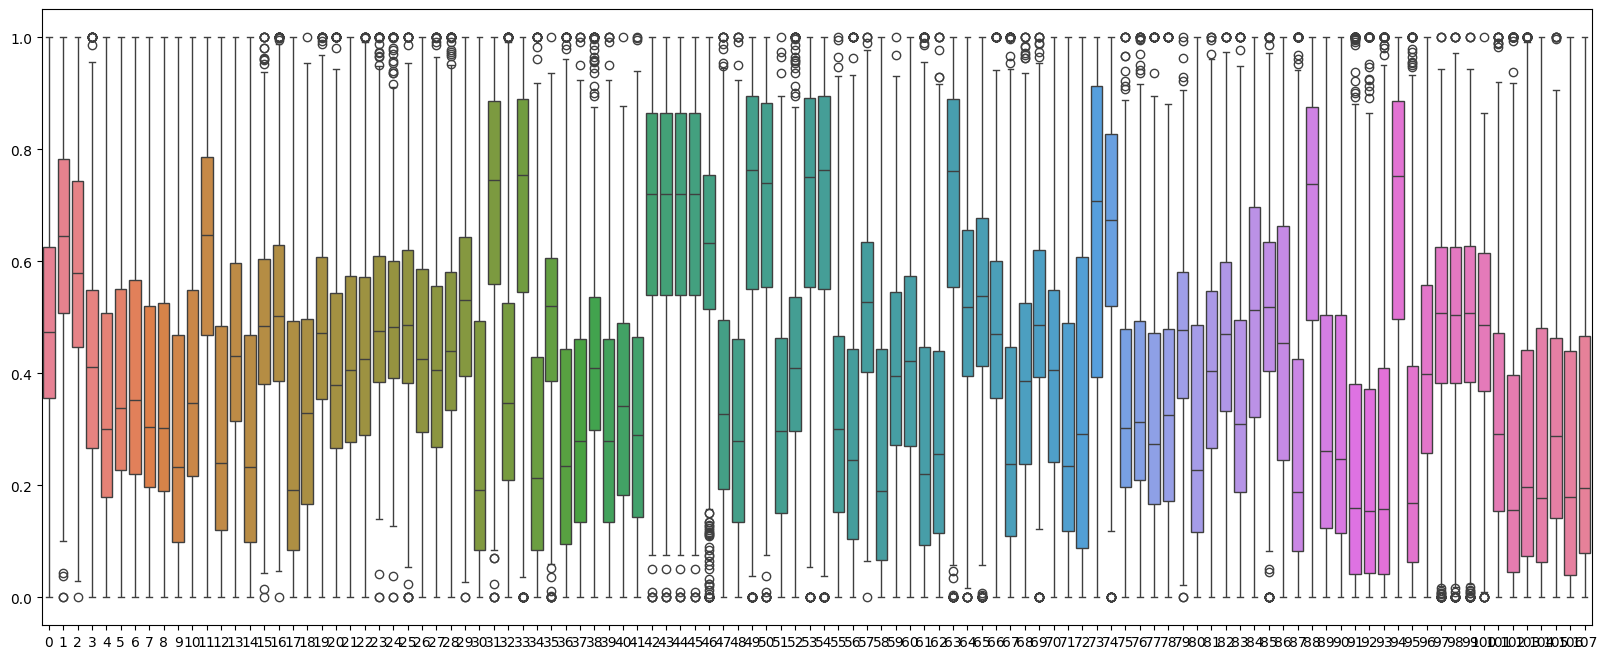

In [9242]:
scaler = MinMaxScaler()
# X_train[continuous_names] = scaler.fit_transform(X_train[continuous_names])
# X_train[continuous_names]

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=scaler.fit_transform(X_train[continuous_names]),ax=ax)

Note: If this method is to be used, outliers have to be removed as they greatly affect the range

##### 2. Z-normalisation
Currently better in this use case to mitigate effect of outliers

After


<Axes: >

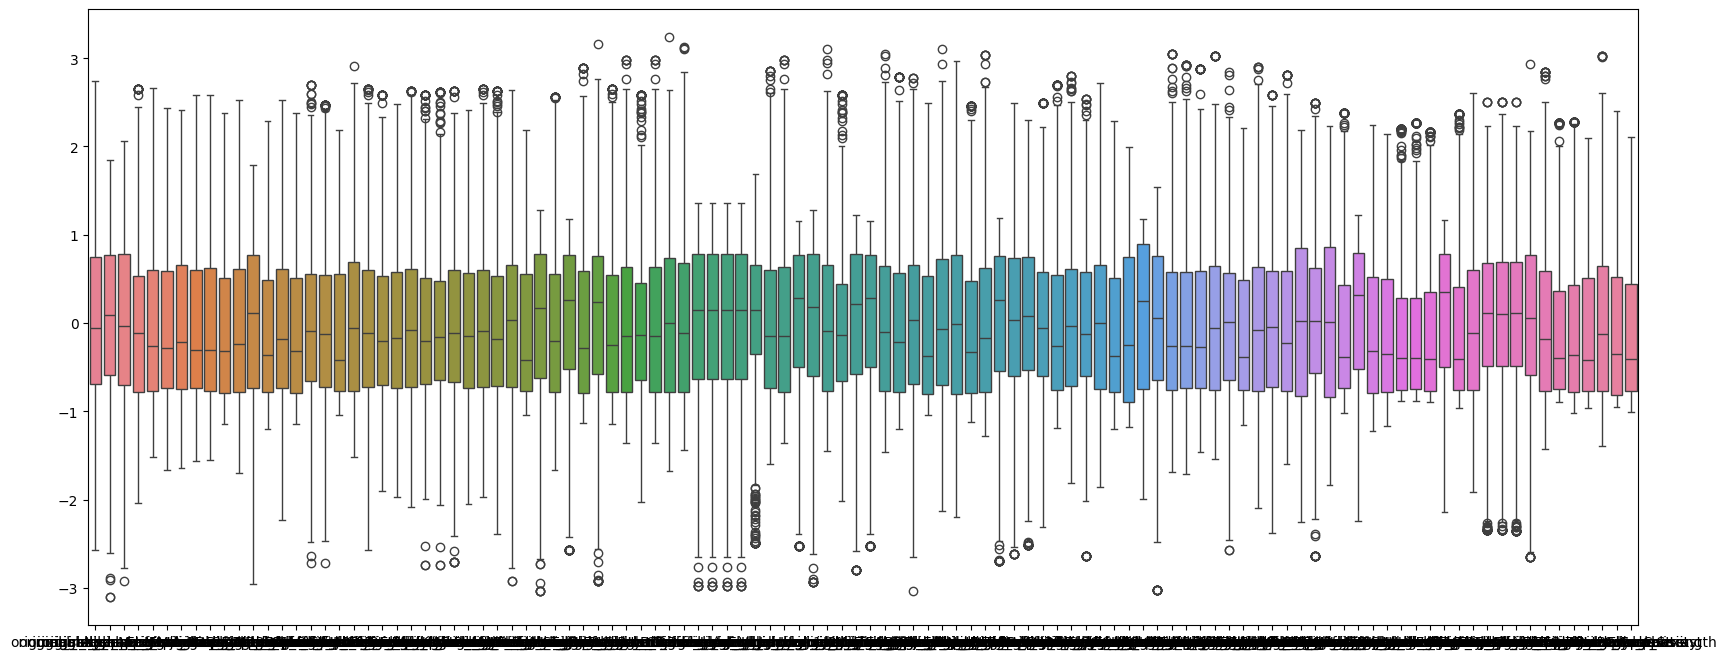

In [9243]:
# Apply Z-Score Normalisation to the columns for the continuous features
z_scaler = StandardScaler()
X_train[continuous_names] = z_scaler.fit_transform(X_train[continuous_names])

print("After")
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

Note: this method is (currently) more applicable as outliers only affect the individual ranges, not the entire dataset range

### 5.b One-hot Encoding
This step parallels Normalisation, as an option for categorical features.

One hot encoding splits the categories in features into multiple features.

Parameters:
- drop_first = True: avoids multicollinearity, preventing dependence between one-hot encoded features

Notes:
- If making 'Age' categorical, avoid one-hot encoding it so we don't cause curse of dimensionality / make the model more computationally expensive.
- In retrospect, potential issue is that this is typically applied to non numerical data so it can be processed numerically.

In [9244]:
# from sklearn.preprocessing import OneHotEncoder # attempt at using model-based method for Pipeline later
# encoder = OneHotEncoder(drop='first')
# encoder.fit(X_train[categorical_names])
# encoder.categories_

In [9245]:
# Apply One-Hot Encoding to the columns for the categorical features

X_train_encoded = pd.get_dummies(X_train, columns = categorical_names, drop_first = True)
# X_train = X_train_encoded

print(f"Before: {X_train.shape}\nAfter: {X_train_encoded.shape}")

Before: (504, 118)
After: (504, 122)


In [9246]:
print(categorical_names)
print(X_train_encoded.select_dtypes(bool).columns)

Index(['ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade', 'Proliferation',
       'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')
Index(['ER_1', 'PgR_1', 'HER2_1', 'TrippleNegative_1', 'ChemoGrade_2',
       'ChemoGrade_3', 'Proliferation_2', 'Proliferation_3', 'HistologyType_2',
       'LNStatus_1', 'TumourStage_2', 'TumourStage_3', 'TumourStage_4',
       'Gene_1'],
      dtype='object')


Note: one-hot encoding is here for demonstration, and is not applied to the dataset

# Feature Selection / Dimensionality reduction
### Note: specification says to keep the following features: 'ER', 'HER2' and 'Gene' 

Feature Selection
- Wrapper methods: forward feature selection, recursive feature elimination
- Embedded methods: LASSO, Decision Trees
- Filter based methods: t-tests, chi square, univariate ANOVA, correlation analysis

Dimensionality Reduction
- Includes: PCA, LDA, manifold learning
- Is manifold learning even applicable? 

First do Correlation analysis for visualisation:

In [9247]:
# corrMatt = X_train.corr(numeric_only=True)

# # Generate a mask for the upper triangle
# mask = np.zeros_like(corrMatt)
# mask[np.triu_indices_from(mask)] = True

# # Set up the matplotlib figure
# fig, ax = plt.subplots(figsize=(50, 50))

# # Generate a custom diverging colormap
# cmap = sns.diverging_palette(260, 10, as_cmap=True)

# # Draw the heatmap with the mask and correct aspect ratio
# sns.heatmap(corrMatt, vmax=1.2, square=False, cmap=cmap, mask=mask,
# ax=ax, annot=True, fmt='.2g', linewidths=1)

Note: the above needs improving and is currently just a visualisation

### Feature Selection
Feature Selection aims to create a subset of the original features optimal for the model building process. This is split into 3 categories.
- Wrapper Methods
- Embedded Methods
- Filter-based Methods

In [9248]:
# Modular variable for number of features to select
n_features_to_select = 10

##### Wrapper Methods
These likely take too long as they iterate through different feature permutations and evaluate them using an evaluation metric. Possibly apply after another method that has already reduced the number of features.

Options:
1. Forward Feature Selection
2. Recursive Feature Elimination



##### 1. Forward Feature Selection

In [9249]:
# from sklearn.feature_selection import SequentialFeatureSelector
# from sklearn.neighbors import KNeighborsClassifier

# # Using KNN as the evaluator
# knn = KNeighborsClassifier(n_neighbors=3)
# sfs = SequentialFeatureSelector(knn, n_features_to_select=n_features_to_select, direction='forward')
# sfs.fit(X_train, y_train)

# cols_sfs = X_train.columns[sfs.get_support()]
# print(f"Top {n_features_to_select} Forward Selection Features: {cols_sfs.tolist()}")

##### 2. Recursive Feature Elimination

In [9250]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# Use a simple estimator
estimator = LogisticRegression(solver='liblinear')
selector_rfe = RFE(estimator, n_features_to_select=n_features_to_select, step=1)
selector_rfe.fit(X_train, y_train)

cols_rfe = X_train.columns[selector_rfe.get_support()]
print(f"Top {n_features_to_select} RFE Features: {cols_rfe.tolist()}")

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the sha

Top 10 RFE Features: ['ER', 'PgR', 'TrippleNegative', 'LNStatus', 'Gene', 'original_firstorder_10Percentile', 'original_firstorder_Variance', 'original_glcm_MaximumProbability', 'original_glrlm_RunEntropy', 'original_glszm_LargeAreaEmphasis']


C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the sha

##### Embedded Methods
Embed Feature Selection into the model process.

Options:
1. LASSO (Regression)
2. Decision Trees / Random Forest

##### 1. LASSO (Regression)


In [9251]:
# LASSO
from sklearn.linear_model import Lasso

# Alpha controls regularization strength (higher alpha -> fewer features selected)
lasso = Lasso(alpha=0.01)
lasso.fit(X_train, y_train) # Using regression target here

# Select features with non-zero weights
lasso_coefs = pd.Series(np.abs(lasso.coef_), index=X_train.columns)
print(f"Top {n_features_to_select} LASSO Features (Regression):\n{lasso_coefs.nlargest(n_features_to_select)}")

Top 10 LASSO Features (Regression):
ER                                              0.378774
TrippleNegative                                 0.344124
PgR                                             0.173778
LNStatus                                        0.134321
original_firstorder_10Percentile                0.073502
Gene                                            0.072049
original_glcm_Imc1                              0.054153
TumourStage                                     0.040582
ChemoGrade                                      0.037986
original_glszm_LargeAreaLowGrayLevelEmphasis    0.033682
dtype: float64


##### 2. Decision Tree / Random Forest

In [9252]:
# Decision Tree/ Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Get importance
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
print(f"Top {n_features_to_select} RF Features:\n{importances.nlargest(n_features_to_select)}")


C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Top 10 RF Features:
PgR                                                0.049989
ER                                                 0.048829
LNStatus                                           0.021733
original_glszm_SizeZoneNonUniformityNormalized     0.018613
original_firstorder_Skewness                       0.015489
original_glrlm_RunLengthNonUniformityNormalized    0.015457
original_ngtdm_Coarseness                          0.015080
TrippleNegative                                    0.014961
original_glszm_ZoneEntropy                         0.014100
original_ngtdm_Contrast                            0.013943
dtype: float64


##### Filter-based Methods
These methods are dependent on the datatypes of features (Xs) and outcomes (ys). Feature datatypes are both categorical and continuous, meaning different methods would have to be applied based on this. The classification outcome, 'pCR (outcome)', is categorical data; meanwhile the regression outcome, 'RelapseFreeSurvival (outcome)', is continuous data.

Note: the above is in theory, as some methods seem to be much more flexible in practice

Note2: theory in this section refers to the lecture content, which is obviously more simplified than in the real world 

Options:

- t-test
- chi-square
- ANOVA
- Correlation Analysis

##### 1. t-test_size

In theory...

Requirements:
- Gaussian Distribution: data is close to gaussian distribution
- Binary Features: data contains binary features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Applicable, features would need to be split

In practice...

##### 2. chi-square 

In theory...

Requirements:
- Categorical Features: dataset contains categorical features
- Categorical Outcome: pCR (outcome) is the categorical outcome

Conclusion: Applicable, features would need to be split

In practice...

Issue: Chi2 uses frequencies which must be positive, causing error. This can be fixed using MinMax normalisation

In [9253]:
#Chi-square

from sklearn.feature_selection import SelectKBest, chi2

# # Apply Chi2 to Categorical Features vs pCR
# chi2_selector = SelectKBest(chi2, k='all') # Calculate for all, then rank
# chi2_selector.fit(X_train, y_train)

# # Create a DataFrame to view scores
# chi2_scores = pd.DataFrame({
#     'Feature': X_train.columns,
#     'Score': chi2_selector.scores_,
#     'P-Value': chi2_selector.pvalues_
# }).sort_values(by='Score', ascending=False)

# print(f"Top {n_features_to_select} Chi-Square Features (Categorical):\n", chi2_scores.head(n_features_to_select))

##### 3. ANOVA 

In theory...

Requirements:
- Categorical Features: dataset contains categorical features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outome

Conclusion: Applicable, features would need to be split

In practice...

SelectKBest can use either f_classif or f_regress, allowing it to work for either type of outcome

In [9254]:
#ANOVA
from sklearn.feature_selection import f_classif

# Apply ANOVA to Continuous Features vs pCR
anova_selector = SelectKBest(f_classif, k='all')
anova_selector.fit(X_train, y_train)

anova_scores = pd.DataFrame({
    'Feature': X_train.columns,
    'Score': anova_selector.scores_,
    'P-Value': anova_selector.pvalues_
}).sort_values(by='Score', ascending=False)

print(f"Top {n_features_to_select} ANOVA Features (Continuous):\n", anova_scores.head(n_features_to_select))

Top 10 ANOVA Features (Continuous):
                                               Feature       Score  \
1                                                  ER  119.682119   
2                                                 PgR  112.041848   
8                                            LNStatus   64.774194   
9                                         TumourStage   27.718792   
89                          original_glrlm_RunEntropy   21.849656   
91    original_glrlm_RunLengthNonUniformityNormalized   19.727937   
5                                          ChemoGrade   19.152003   
76  original_gldm_LargeDependenceLowGrayLevelEmphasis   18.583046   
92                       original_glrlm_RunPercentage   18.146315   
74              original_gldm_LargeDependenceEmphasis   16.448086   

         P-Value  
1   3.949750e-25  
2   9.035337e-24  
8   6.118458e-15  
9   2.083732e-07  
89  3.793820e-06  
91  1.099097e-05  
5   1.469249e-05  
76  1.958488e-05  
92  2.443100e-05  
74  5.795590e

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


##### 4. Correlation Analysis

In theory...

Requirements:
- Continuous Feature: dataset contains continuous features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Not Applicable, outcome is categorical

In practice...

In [9255]:
# Correlation analysis

# Calculate Pearson correlation with RelapseFreeSurvival
corr_values = X_train.corrwith(y_train).abs().sort_values(ascending=False)
print(f"Top {n_features_to_select} Correlated Features (vs RelapseFreeSurvival):\n", corr_values.head(n_features_to_select))

Top 10 Correlated Features (vs RelapseFreeSurvival):
 Age               NaN
ChemoGrade        NaN
ER                NaN
Gene              NaN
HER2              NaN
HistologyType     NaN
LNStatus          NaN
PgR               NaN
Proliferation     NaN
TrippleNegative   NaN
dtype: float64


##### Chosen Feature Selection Method:
Currenty Recursive Feature Selection as it contains all 3 of the recommended features to select: HER2, Gene and ER.

Note: This is a naive assumption, ideally choose based on results from evaluation.

In [9256]:
feature_selection_cols = cols_rfe.tolist()

<Axes: >

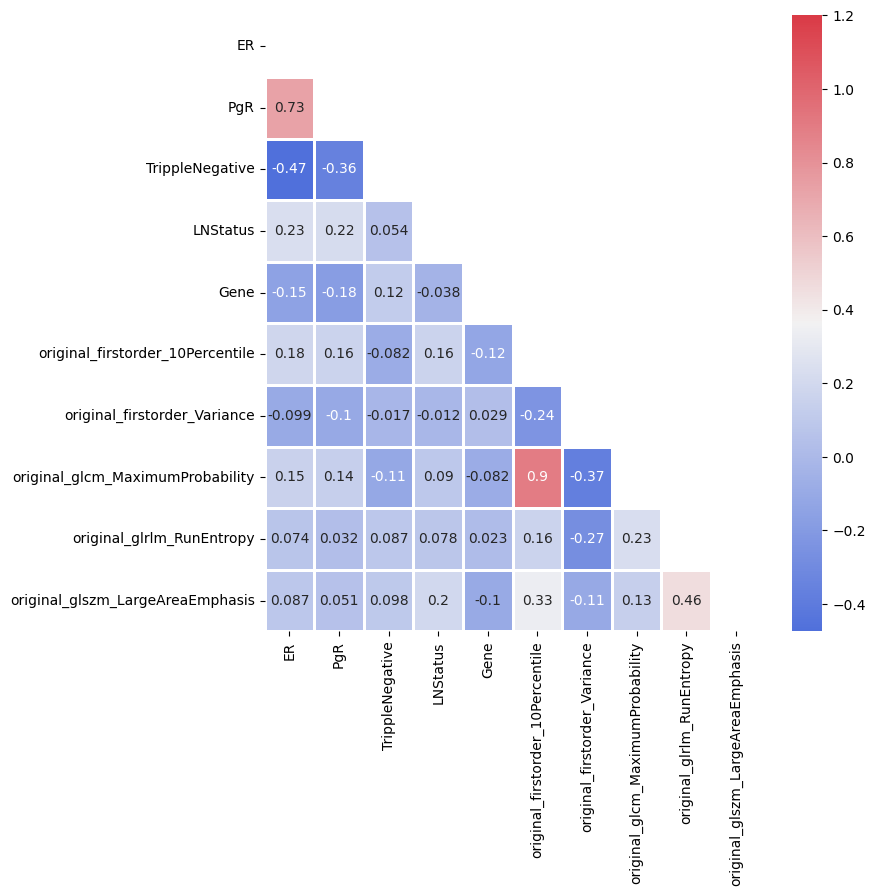

In [9257]:
# Feature Correlation Matrix for Feature Selection columns

corrMatt = X_train[feature_selection_cols].corr(numeric_only=True)

# Generate a mask for the upper triangle
mask = np.zeros_like(corrMatt)
mask[np.triu_indices_from(mask)] = True

# Set up the matplotlib figure
fig, ax = plt.subplots(figsize=(8, 8))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(260, 10, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corrMatt, vmax=1.2, square=False, cmap=cmap, mask=mask,
ax=ax, annot=True, fmt='.2g', linewidths=1)

### Dimensionality Reduction
Reduces the dimension of the data by generating new features from the old ones. This reduces interpretability, as new features are not the same as the old ones, hence we lose some understanding of the dataset

##### VAE (Variational AutoEncoder)
VAE as a feature extraction tool:

Method Overview
- Encoder: Compresses the high-dimensional input data (x) into a probabilistic latent space defined by a mean (μ) and variance (σ).

- Sampling: Uses the "reparameterization trick" to sample a latent vector z from the distribution N(μ,σ).

- Decoder: Attempts to reconstruct the original input from z.

- Dimensionality Reduction: Once trained, discard the decoder and use the Encoder to transform new data into the low-dimensional latent vector z (or simply the mean μ), which serves as the reduced dataset.

In [9258]:
# VAE - Variational Auto-Encoder
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K

input_dim = X_train.shape[1]
latent_dim = 5 # Target dimensions

# Encoder
encoder_inputs = layers.Input(shape=(input_dim,))
x = layers.Dense(64, activation="relu")(encoder_inputs)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)



##### PCA (Principal Component Analysis)
This unsupervised learning method fits data to a new pair of axes so that it can be split using less features. This is done by calculating the mean (origin of new axes), covariance matrix (ellipse that contains the data), eigenvalues and eigenvectors of the covariance matrix (pair of new axes). 

scikit-learn pca has the following approach:
- n_components is the desired output feature total

In [9259]:
from sklearn.decomposition import PCA

pca = PCA(n_components=n_features_to_select)
Xs_pca = pca.fit_transform(X_train)
PCA_df = pd.DataFrame(Xs_pca, columns=['PCA_'+str(i+1) for i in range(Xs_pca.shape[1])])


PCA_df

,PCA_1,PCA_2,PCA_3,PCA_4,PCA_5,PCA_6,PCA_7,PCA_8,PCA_9,PCA_10
0,7.025598,-1.791706,-3.555200,1.220850,0.390321,-1.473933,-0.976622,-1.191331,0.507890,-1.002252
1,-4.177052,-4.562577,-3.757518,2.662719,-0.748889,0.811204,0.618060,1.216364,-0.491106,0.487227
2,2.930121,-3.781477,5.473158,2.837377,-1.189323,1.202815,-0.935227,-0.232442,1.365932,-0.156658
3,-6.115302,-6.199852,-5.002550,-0.007230,0.710311,1.233343,0.439350,0.318855,-0.729190,-0.697919
4,-3.606811,5.332072,3.621458,0.291951,0.421807,4.644345,-1.495675,-2.989607,0.129172,-0.621932
...,...,...,...,...,...,...,...,...,...,...
499,-4.229591,6.888121,-1.775243,3.217618,-0.035385,-2.307450,1.799554,0.606758,-0.354118,1.295395
500,7.518787,9.005224,0.372327,-2.316937,0.800624,-0.766082,1.664211,0.699749,-0.662925,-1.425625
501,3.717602,0.065977,-0.262660,1.883308,-0.496260,-0.504042,-0.155027,0.006559,-0.950221,-1.019628
502,-1.087772,1.595782,-2.413809,2.241254,0.008049,-1.156847,-0.003534,-0.391215,-0.332101,-0.817129


Note: do we concatenate HER2, ER and Gene to PCA features

In [9260]:
# plt.figure(figsize=(6,6))
# plt.plot(PCA_df['PCA_1'][dataset_y_clf == 1], PCA_df['PCA_2'][dataset_y_clf == 1], 'ro', alpha = 0.7, markeredgecolor = 'k')
# plt.plot(PCA_df['PCA_1'][dataset_y_clf == 0], PCA_df['PCA_2'][dataset_y_clf == 0], 'bo', alpha = 0.7, markeredgecolor = 'k')
# plt.xlabel('PCA_1')
# plt.ylabel('PCA_2')
# plt.legend(['pCR','not pCR'])

##### LDA (Linear Discriminant Analysis)
This supervised learning method projects data to a new pair of axes that helps split it into different classes. This is done by maximising the variance between data of different classes to separate them, and minimising the mean to keep datapoints within the same class together

In [9261]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

lda = LDA()
lda.fit(X = X_train, y = y_train)

lda.predict(X=[X_train.loc[1]])

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearDiscriminantAnalysis was fitted with feature names
  warnings.warn(


array([1])

# Machine Learning Method Development

Steps:
1. Sample New Data
2. Test Data Pipeline
3. Machine Learning Methods

### 1. Process Test Data
1. Preprocessing Pipeline
2. Apply Feature Selection


#### 1. Preprocessing Pipeline
- Create Pipeline that transforms test dataset using every desired method following train-test split
- Apply Pipeline

In [9262]:
transformers = {
    # "imputer_mode": (imputer_mode, categorical_names),
    # "imputer_median": (imputer_median, continuous_names),
    "imputer_knn": (imputer_knn, X_train.columns),
    "z_scaler": (z_scaler, continuous_names)
}

# Imputing 'pCR (Outcome)' using mode (make sure  this is the correct transformer)
y_test = pd.DataFrame(imputer_mode.fit_transform(pd.DataFrame(y_test)), columns=['pCR (outcome)'], index=y_test.index)

outlier_iqr(X_test, continuous_names) # this is manual so re implement this in any new notebooks
for key, value in transformers.items():
    print(key)
    X_test[value[1]] = value[0].transform(X_test[value[1]])
X_test

imputer_knn
z_scaler


,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
280,1.202962,0.0,0.0,0.0,1.0,3.0,2.0,1.0,0.0,3.0,...,-0.719104,-0.721636,-0.331494,0.498453,-0.863043,-0.687104,0.002029,2.001595,2.083850,0.180479
387,0.826228,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,3.0,...,-2.185137,-2.219006,-1.725923,-0.911017,-0.854890,-1.019928,3.856935,-1.389938,-0.955197,-1.010014
313,-1.186322,0.0,0.0,0.0,1.0,3.0,2.0,1.0,0.0,2.0,...,-0.176445,-0.162456,0.763311,-0.925135,0.757482,2.134705,-0.926518,1.164979,1.542116,-0.927470
1,-1.285462,1.0,1.0,0.0,0.0,3.0,3.0,1.0,1.0,2.0,...,0.335517,0.365091,0.428491,1.008302,-0.568952,-0.488929,-0.500578,-0.630828,-0.781909,-0.453806
35,-0.690620,1.0,1.0,1.0,0.0,2.0,2.0,1.0,1.0,2.0,...,0.479273,0.513223,-0.156078,1.643194,-0.837210,-0.886425,0.969602,-0.518528,-0.743324,1.256053
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149,0.235708,1.0,1.0,0.0,0.0,2.0,1.0,2.0,0.0,4.0,...,0.488651,0.522886,0.820032,0.992210,0.477758,2.091759,-0.906560,-0.367869,-0.640626,-0.910784
301,1.193048,0.0,0.0,0.0,1.0,3.0,3.0,1.0,0.0,2.0,...,0.411059,0.442932,0.103511,-0.391726,-0.575564,-0.205632,-0.638152,0.722665,0.465313,-0.599333
78,-0.474628,1.0,1.0,0.0,0.0,2.0,1.0,2.0,1.0,3.0,...,0.518641,0.553767,0.866168,1.487237,-0.366346,1.048362,-0.862468,-0.249882,-0.553069,-0.861562
71,-0.872818,0.0,0.0,0.0,1.0,2.0,1.0,1.0,1.0,4.0,...,-1.223519,-1.241405,-1.020502,-1.373375,0.757482,-0.960454,3.218791,-1.371711,-0.955131,3.116287


Note: the above method does not use a pipeline as there is no elegant way to transform specific columns using specific column names in a pipeline

Issues with pipeline:
- ColumnTransformer returns an ndarray (no column names), causing subsequent ColumnTransformers to fail
- Pipeline has to be fitted to new data before calling transform, re-fitting to test data instead of training data (despite above issue)

Evidence of issues is below, commented out code...

In [9263]:
# # Preprocess the new data (MUST use the same scaling/imputation fitted objects)
# # Assuming 'new_features' are the preprocessed features ready for the model

# from sklearn.pipeline import make_union, make_pipeline, Pipeline
# from sklearn.preprocessing import FunctionTransformer
# from sklearn.compose import ColumnTransformer

# pipeline = make_pipeline()
# pipeline.__sklearn_is_fitted__
# # outlier removal:
# # outlier_iqr(X_test, continuous_names)

# # data imputation: SimpleImputer median|mode DONE
# ct_imputations = ColumnTransformer([("mode", imputer_mode, categorical_names), ("median", imputer_median, continuous_names)])
# pipeline.steps.append(["imputations", ct_imputations])

# # normalisation: standard scaler
# ct_norm = ColumnTransformer([("z-norm", standard_scaler, continuous_names)], verbose_feature_names_out=True)
# pipeline.steps.append(["z-norm", ct_norm])

# print(pipeline.steps)
# # one-hot encoding
# # pipeline.steps.append(["one-hot", FunctionTransformer(pd.get_dummies, kw_args={"columns":categorical_names, "drop_first":True})])

# # maybe
#     # PCA
#     # LDA

# X_test = pipeline.transform(X_test)
# X_test = pd.DataFrame(X_test)
# X_test

In [9264]:
# Use joblib to export pipeline

In [9265]:
# need to preprocess y as well
    # null values

#### 2. Apply Feature Selection

### 2. Machine Learning Models

##### Linear:
- Multivariate Linear Regression
- ~~Logistic Regression~~ (Took over 10 min until interrupted) | Classification
- Naïve Bayes (don't forget different types) | Classification
- K-Nearest Neighbour (KNN) | Classification
- Support Vector Classifier/Regressor

##### Non-Linear:
- Kernel Support Vector Classifier/Regressior
- Decision Tree Classifier/Regressor
- Random Forest Classifier/Regressor

##### Deep Learning Models:
- Multilayer Perceptron Classifier/Regressor
- Convolution Neural Networks -------------------------------------------------

In [9266]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier


results = {}

#### Logistic Regression

In [9267]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression
log_reg = LogisticRegression(max_iter=100)
log_reg.fit(X_train, y_train)
results['Logistic Regression Acc'] = log_reg.score(X_test, y_test)

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Naïve Bayes
Different types: gaussian, bernoulli, (counts), (another one I forgot)

In [9268]:
# Naïve Bayes (Gaussian)
nb = GaussianNB()
nb.fit(X_train, y_train)
results['Naive Bayes Acc'] = nb.score(X_test, y_test)

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


#### K Nearest Neighbour
Value of K hyperparameter

In [9269]:
# KNN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
results['KNN Acc'] = knn.score(X_test, y_test)

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neighbors\_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


#### Support Vector Classifier
Hard Margin, soft margin

In [9270]:
# Hard Margin SVM (Approximated with large C)
svm_hard = SVC(kernel='linear', C=100)
svm_hard.fit(X_train, y_train)
results['Hard Margin SVM Acc'] = svm_hard.score(X_test, y_test)

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


#### Kernel SVC

In [9271]:
# Kernel SVM (RBF)
svm_kernel = SVC(kernel='rbf')
svm_kernel.fit(X_train, y_train)
results['Kernel SVM Acc'] = svm_kernel.score(X_test, y_test)

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


#### Decision Tree
Reasons for params

In [9272]:
# Decision Tree
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
results['Decision Tree Acc'] = dt.score(X_test, y_test)

#### Random Forest
Reasons for params

In [9273]:
# Random Forest
rf = RandomForestClassifier(n_estimators=10)
rf.fit(X_train, y_train)
results['Random Forest Acc'] = rf.score(X_test, y_test)

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


#### Multi-Layer Perceptron Classifier
Explain Parameters

In [9274]:
# MLP
mlp = MLPClassifier(hidden_layer_sizes=(50, 50), max_iter=500)
mlp.fit(X_train, y_train)
results['MLP Acc'] = mlp.score(X_test, y_test)

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1124: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


#### Results

In [9275]:
print("Model execution successful. Results on dummy test set:")
for result in results.items():
    print(result)

Model execution successful. Results on dummy test set:
('Logistic Regression Acc', 0.675)
('Naive Bayes Acc', 0.6125)
('KNN Acc', 0.525)
('Hard Margin SVM Acc', 0.6375)
('Kernel SVM Acc', 0.775)
('Decision Tree Acc', 0.6625)
('Random Forest Acc', 0.725)
('MLP Acc', 0.725)


#### Method Pipeline

In [9276]:
# Export all the methods using joblib/pickle

# Method Evaluation

Options:

- K Fold Cross Validation
- Confusion Matrix
- Precision/Recall/Specificity/Sensitivity
- (Balanced) Classification Accuracy
- ROC curve?

K Fold Cross Validation
- potentially use method pipeline like in cw 1? 

In [9277]:
# FINALLY Add hyperlinks to notebook

In [9278]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, KFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

In [9279]:
models = {
    "Logistic Regression": log_reg,
    "Naive Bayes (Gaussian)": nb,
    "KNN (k=3)": knn,
    # "SVM Hard (linear, C=100)": svm_hard,
    "SVM RBF": svm_kernel,
    "Decision Tree": dt,
    "Random Forest (n=10)": rf,
    "MLP (50,50)": mlp,
    "LDA": lda
}


In [9280]:
# X = dataset_x_all.copy()
# y = dataset_y_clf.copy()

In [9281]:
# X = X.replace(999, np.nan)

In [9282]:
# df_all = pd.concat([X, y], axis=1)


# X = df_all['Gene'].dropna()

# Categorical: mode
# X[categorical_names] = imputer_mode.fit_transform(X[categorical_names])

# Continuous: median
# X[continuous_names] = imputer_median.fit_transform(X[continuous_names])

In [9283]:
# X_clean = X
# y_clean = y

# print("Original class counts:\n", dataset_y_clf.value_counts())
# print("After imputation class counts:\n", y_clean.value_counts())

In [9284]:
# 1) Join features + labels, drop any rows with NaNs, then split again

df_all = pd.concat([dataset_x_all, dataset_y_clf], axis=1)

# Drop rows where ANY column (feature or label) is NaN
df_all_clean = df_all.dropna().reset_index(drop=True)

outlier_iqr(X_df=dataset_x_all, continuous_cols=continuous_names)
for key, value in transformers.items():
    print(key)
    X_test[value[1]] = value[0].fit_transform(X_test[value[1]])

# Split back into X and y
X_clean = df_all_clean.drop(columns=['pCR (outcome)'])   # features
y_clean = df_all_clean['pCR (outcome)']                  # labels

print("Original shape:", dataset_x_all.shape[0])
print("After dropping NaNs:", X_clean.shape[0])

imputer_knn
z_scaler
Original shape: 400
After dropping NaNs: 308


In [9285]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score

print("=== K-Fold CV: balanced accuracy on CLEANED TRAIN set ===")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# For binary classification: 2x2 confusion matrices
conf_matrices = {name: np.zeros((2, 2), dtype=int) for name in models.keys()}

for name, model in models.items():
    print(f"\n== {name} ==")
    fold = 1

    for train_index, test_index in skf.split(X_clean, y_clean):
        X_train_fold = X_clean.iloc[train_index]
        X_test_fold  = X_clean.iloc[test_index]
        y_train_fold = y_clean.iloc[train_index]
        y_test_fold  = y_clean.iloc[test_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_fold = model.predict(X_test_fold)

        # Confusion matrix for this fold (binary labels)
        cm_fold = confusion_matrix(y_test_fold, y_pred_fold, labels=[0, 1])
        conf_matrices[name] += cm_fold

        acc = accuracy_score(y_test_fold, y_pred_fold)
        bal_acc = balanced_accuracy_score(y_test_fold, y_pred_fold)

        print(f"\nFold {fold} confusion matrix:\n{cm_fold}")
        print(f"Fold {fold} accuracy:          {acc:.3f}")
        print(f"Fold {fold} balanced accuracy: {bal_acc:.3f}")

        fold += 1

    # After all folds
    print(f"\nAggregated confusion matrix over all folds for {name}:\n{conf_matrices[name]}")


=== K-Fold CV: balanced accuracy on CLEANED TRAIN set ===

== Logistic Regression ==

Fold 1 confusion matrix:
[[49  2]
 [11  0]]
Fold 1 accuracy:          0.790
Fold 1 balanced accuracy: 0.480

Fold 2 confusion matrix:
[[49  2]
 [11  0]]
Fold 2 accuracy:          0.790
Fold 2 balanced accuracy: 0.480

Fold 3 confusion matrix:
[[51  0]
 [11  0]]
Fold 3 accuracy:          0.823
Fold 3 balanced accuracy: 0.500

Fold 4 confusion matrix:
[[50  1]
 [10  0]]
Fold 4 accuracy:          0.820
Fold 4 balanced accuracy: 0.490

Fold 5 confusion matrix:
[[50  1]
 [ 9  1]]
Fold 5 accuracy:          0.836
Fold 5 balanced accuracy: 0.540

Aggregated confusion matrix over all folds for Logistic Regression:
[[249   6]
 [ 52   1]]

== Naive Bayes (Gaussian) ==

Fold 1 confusion matrix:
[[ 8 43]
 [ 1 10]]
Fold 1 accuracy:          0.290
Fold 1 balanced accuracy: 0.533

Fold 2 confusion matrix:
[[ 4 47]
 [ 0 11]]
Fold 2 accuracy:          0.242
Fold 2 balanced accuracy: 0.539

Fold 3 confusion matrix:
[[ 2

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stab


Fold 1 confusion matrix:
[[45  6]
 [ 8  3]]
Fold 1 accuracy:          0.774
Fold 1 balanced accuracy: 0.578

Fold 2 confusion matrix:
[[43  8]
 [ 3  8]]
Fold 2 accuracy:          0.823
Fold 2 balanced accuracy: 0.785

Fold 3 confusion matrix:
[[42  9]
 [ 6  5]]
Fold 3 accuracy:          0.758
Fold 3 balanced accuracy: 0.639

Fold 4 confusion matrix:
[[45  6]
 [ 5  5]]
Fold 4 accuracy:          0.820
Fold 4 balanced accuracy: 0.691

Fold 5 confusion matrix:
[[44  7]
 [ 4  6]]
Fold 5 accuracy:          0.820
Fold 5 balanced accuracy: 0.731

Aggregated confusion matrix over all folds for Decision Tree:
[[219  36]
 [ 26  27]]

== Random Forest (n=10) ==

Fold 1 confusion matrix:
[[47  4]
 [ 9  2]]
Fold 1 accuracy:          0.790
Fold 1 balanced accuracy: 0.552

Fold 2 confusion matrix:
[[51  0]
 [10  1]]
Fold 2 accuracy:          0.839
Fold 2 balanced accuracy: 0.545

Fold 3 confusion matrix:
[[47  4]
 [10  1]]
Fold 3 accuracy:          0.774
Fold 3 balanced accuracy: 0.506

Fold 4 confus